# Семинар 4. Линейная регрессия

На Auto MPG сравним константный прогноз, метод наименьших квадратов (OLS),
Ridge и Lasso. Проверим, помогают ли квадраты и взаимодействия признаков
предсказывать экономичность автомобиля. Для запуска положите **auto-mpg.csv**
рядом с ноутбуком.

Порядок работы: откладываем test, сравниваем модели по кросс-валидации на
train, затем проверяем выбранную модель на test.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.preprocessing import StandardScaler

SEED = 42

## 1. Данные и разбиение

**mpg** — сколько миль автомобиль проезжает на галлоне топлива. Чем выше
mpg, тем экономичнее автомобиль. Символ **?** в CSV означает пропуск.
**origin** — код региона, который будем кодировать индикаторами 0/1.
Название автомобиля исключим из базовой модели. В другой модели из него
можно было бы извлечь, например, производителя.

Случайное разбиение подходит для прогноза на похожих автомобилях.

In [2]:
cars = pd.read_csv("auto-mpg.csv", na_values="?")
X = cars.drop(columns=["mpg", "car name"])
y = cars["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED
)

display(cars.loc[X_train.index].head())
display(X_train.isna().sum().rename("Пропуски на train"))

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
245,36.1,4,98.0,66.0,1800,14.4,78,1,ford fiesta
110,22.0,4,108.0,94.0,2379,16.5,73,3,datsun 610
16,18.0,6,199.0,97.0,2774,15.5,70,1,amc hornet
66,17.0,8,304.0,150.0,3672,11.5,72,1,amc ambassador sst
153,18.0,6,250.0,105.0,3459,16.0,75,1,chevrolet nova


cylinders       0
displacement    0
horsepower      5
weight          0
acceleration    0
model year      0
origin          0
Name: Пропуски на train, dtype: int64

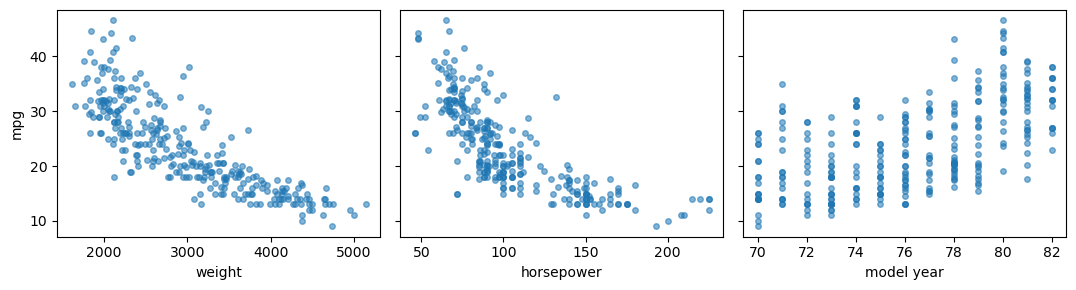

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, feature in zip(axes, ["weight", "horsepower", "model year"]):
    ax.scatter(X_train[feature], y_train, alpha=0.55, s=16)
    ax.set_xlabel(feature)
axes[0].set_ylabel("mpg")
fig.tight_layout()
plt.show()

Похожа ли зависимость на прямую?
График показывает связь двух переменных. Коэффициент при весе в линейной
модели описывает изменение прогноза при фиксированных остальных признаках.


### Подготовка признаков внутри Pipeline

Сначала заполним пропуски в числовых столбцах медианой, затем построим
признаки и стандартизируем их перед обучением. В каждом CV-разбиении
Pipeline оценивает медианы, параметры масштаба и категории на обучающей
части и применяет их к валидационной.

Единицы признаков меняют величину весов. 
Масштабирование приводит числовые признаки к сопоставимому масштабу перед
штрафованием весов. Индикаторы региона оставим в масштабе 0/1, а цель — в mpg.

In [4]:
numeric_columns = X_train.columns.drop("origin").tolist()


def make_pipeline(model, degree=1):
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scale", StandardScaler()),
    ]) # do not include bias here, as it will be included in OLS
    preprocess = ColumnTransformer([
        ("numeric", numeric, numeric_columns),
        ("region", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        ), ["origin"]),
    ])
    return Pipeline([("preprocess", preprocess), ("model", model)])

- Степень 1 сохраняет исходные числовые признаки. Степень 2 добавляет квадраты
и произведения. Для двух признаков получим $x_1,x_2,x_1^2,x_1x_2,x_2^2$.
Режим **interaction_only=True** оставил бы произведение $x_1x_2$ без
квадратов. Модель остаётся линейной по весам.
- Категории кодируются отдельно (степени брать бесполезно, но можно брать интеракции).
- Свободный член оцениваем в при обучении модели, поэтому дополнительный столбец единиц пока
не включаем. 
- При полном one-hot кодировании возникает мультиколлинеарность - три столбца one-hot вместе со столбцом единиц для свободного члена линейно зависимы:

$$d₁+d₂+d₃-1=0.$$

Поэтому отдельные веса OLS при них не определены однозначнo.
Solver находит один из возможных наборов весов.
При этом удаление одного индикатора некорректно, так как регуляризация будет неодинаково штрафовать разные категории.

## 2. Baseline, OLS и метрики

Baseline предсказывает средний mpg обучающей выборки. OLS подбирает веса
и свободный член, минимизируя сумму квадратов ошибок на train.

Для ошибок $e_i=y_i-\hat y_i$:

$$
\mathrm{MAE}=\frac1n\sum_i|e_i|,\qquad
\mathrm{MSE}=\frac1n\sum_i e_i^2,\qquad
\mathrm{RMSE}=\sqrt{\mathrm{MSE}}.
$$


$$
R^2=1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}.
$$

Метрика $R^2$ сравнивает сумму квадратов ошибок модели с суммой квадратов
ошибок константного прогноза, равного среднему ответу на **оцениваемой**
выборке. При $R^2=0.8$ сумма квадратов ошибок модели на 80% меньше.

Наш baseline ($\bar y$) предсказывает средний ответ на **обучающей** выборке. Если
средние на обучении и на оцениваемой выборке различаются, у baseline
сумма квадратов ошибок больше, чем в знаменателе, тогда $R^2$ отрицателен. Если средние совпадают, $R^2$ равен нулю.

Дополнительная метрика $\mathrm{MAPE}=\frac1n\sum_i
\frac{|e_i|}{\max(\varepsilon,|y_i|)}$. . Малые $|y_i|$ могут сильно влиять
на результат. Для выбора модели здесь используем RMSE.

**Вопрос.** Что произойдёт с MAE, RMSE и $R^2$, если перевести ответы и
предсказания из mpg в километры на литр, умножив на одну константу?

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"RMSE": "neg_root_mean_squared_error", "R2": "r2"}


def evaluate(estimator, params):
    search = GridSearchCV(
        estimator, params, cv=cv, scoring=scoring, refit=False,
        return_train_score=True, error_score="raise",
    ) # error_score="raise" to find any errors
    search.fit(X_train, y_train)
    results = pd.DataFrame(search.cv_results_)
    return results.assign(**{
        "Train RMSE": -results["mean_train_RMSE"],
        "CV RMSE": -results["mean_test_RMSE"],
        "CV RMSE std": results["std_test_RMSE"],
        "CV R²": results["mean_test_R2"],
    }) # neg_root_mean_squared_error - is negative, need to revert


baseline = evaluate(DummyRegressor(strategy="mean"), {})
ols = evaluate(make_pipeline(LinearRegression()), {})
baseline_comparison = pd.concat(
    [baseline, ols], keys=["Среднее train", "OLS (степень 1)"]
).droplevel(1)
display(baseline_comparison[["CV RMSE", "CV R²"]].round(3))

,CV RMSE,CV R²
Среднее train,7.899,-0.019
OLS (степень 1),3.513,0.794


В таблице усредняем метрики по пяти валидационным частям.
RMSE возвращается со знаком минус, поскольку в slkearn scoring всегда максимизируется. 

## 3. Степень признаков и сила регуляризации

Для $\mathrm{RSS}=\sum_i(y_i-\hat y_i)^2$ функции цели в sklearn имеют вид:

$$
\text{Ridge:}\;\mathrm{RSS}+\alpha\sum_j w_j^2,\qquad
\text{Lasso:}\;\frac{\mathrm{RSS}}{2n}+\alpha\sum_j|w_j|.
$$

Свободный член не входит в штраф. У методов разные штрафы и нормировка
ошибки, поэтому одинаковое число $\alpha$ не задаёт одинаковую силу
регуляризации. Используем отдельные сетки значений.
[Документация Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
и [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html).

**Предскажите.** Что произойдёт с обучающей ошибкой OLS при добавлении
признаков? Как изменятся веса при очень большом $\alpha$?

In [6]:
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=100_000, tol=1e-3),
}
alpha_grids = {
    "Ridge": np.logspace(-4, 4, 17), # logspace - 10^np.linspace(..)
    "Lasso": np.logspace(-3, 1, 13),
}

tables = []
for name, model in models.items():
    for degree in [1, 2]:
        params = {"model__alpha": alpha_grids[name]} if name != "OLS" else {}
        scores = evaluate(make_pipeline(model, degree), params)
        scores["Модель"] = name
        scores["Степень"] = degree
        scores["alpha"] = scores.get("param_model__alpha", np.nan)
        tables.append(scores)

results = pd.concat(tables, ignore_index=True)
results["alpha"] = results["alpha"].astype(float)
best_indices = results.groupby(["Модель", "Степень"])["CV RMSE"].idxmin()
comparison = results.loc[best_indices].sort_values("CV RMSE")
columns = [
    "Модель", "Степень", "alpha", "Train RMSE", "CV RMSE", "CV RMSE std",
    "CV R²",
]
display(comparison[columns].round(3))

,Модель,Степень,alpha,Train RMSE,CV RMSE,CV RMSE std,CV R²
23,Ridge,2,0.010,2.651,2.956,0.157,0.855
49,Lasso,2,0.001,2.669,2.969,0.144,0.854
1,OLS,2,NaN,2.626,3.070,0.305,0.846
42,Lasso,1,0.100,3.395,3.497,0.253,0.797
10,Ridge,1,1.000,3.359,3.510,0.292,0.795
0,OLS,1,NaN,3.358,3.513,0.296,0.794


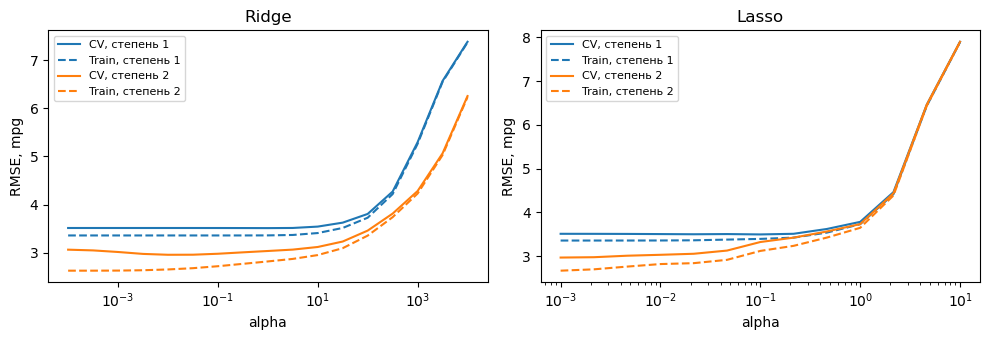

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, alpha_grids):
    for degree in [1, 2]:
        scores = results[
            (results["Модель"] == name) & (results["Степень"] == degree)
        ]
        line, = ax.semilogx(
            scores["alpha"], scores["CV RMSE"], label=f"CV, степень {degree}"
        )
        ax.semilogx(
            scores["alpha"], scores["Train RMSE"], "--",
            color=line.get_color(), label=f"Train, степень {degree}",
        )
    ax.set(title=name, xlabel="alpha", ylabel="RMSE, mpg")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

- Сплошные линии показывают CV-ошибку, пунктир — ошибку на обучающих частях
тех же разбиений. При большом штрафе прогноз приближается к константе,
поэтому обе ошибки могут вырасти.

- В таблице для каждой пары «модель и степень» показана строка с минимальным
средним CV RMSE. **CV RMSE std** показывает разброс ошибок по частям.
- Если минимум на краю сетки, полезно проверить соседние значения по CV.
Однако при очень маленьком штрафе Lasso на полиномиальных признаках решатель может
не уложиться в заданное число итераций.

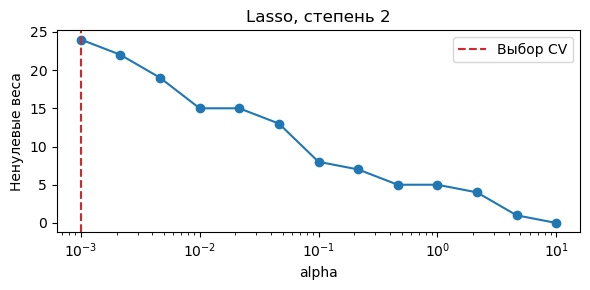

numeric__model year^2                 26.485367
numeric__model year                  -24.274047
numeric__acceleration                -13.224730
numeric__cylinders horsepower         12.921613
numeric__acceleration model year      10.031553
numeric__cylinders^2                  -8.323263
numeric__displacement weight           7.864863
numeric__horsepower weight            -7.138232
numeric__weight model year            -6.327738
numeric__weight^2                      5.671655
numeric__cylinders acceleration        5.444482
numeric__displacement                 -3.854113
numeric__displacement acceleration    -3.477723
numeric__acceleration^2                3.451998
numeric__cylinders model year         -3.310206
numeric__displacement model year       3.274435
numeric__weight acceleration          -2.769314
numeric__horsepower model year        -2.678247
numeric__displacement^2               -2.115677
numeric__horsepower^2                 -1.854130
region__origin_1                      -1

Нулевые веса: 6 из 30


,Признак с нулевым весом
0,numeric__cylinders
1,numeric__horsepower
2,numeric__weight
3,numeric__cylinders displacement
4,numeric__displacement horsepower
5,region__origin_3


In [8]:
lasso_row = comparison[
    (comparison["Модель"] == "Lasso") & (comparison["Степень"] == 2)
].iloc[0]

lasso_pipe = make_pipeline(clone(models["Lasso"]), degree=2)
counts = []
for alpha in alpha_grids["Lasso"]:
    lasso_pipe.set_params(model__alpha=alpha).fit(X_train, y_train)
    counts.append(np.count_nonzero(lasso_pipe.named_steps["model"].coef_))

fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogx(alpha_grids["Lasso"], counts, "o-")
ax.axvline(lasso_row["alpha"], ls="--", color="tab:red", label="Выбор CV")
ax.set(xlabel="alpha", ylabel="Ненулевые веса", title="Lasso, степень 2")
ax.legend()
fig.tight_layout()
plt.show()

lasso_pipe.set_params(**lasso_row["params"]).fit(X_train, y_train)
names = lasso_pipe.named_steps["preprocess"].get_feature_names_out()
weights = pd.Series(lasso_pipe.named_steps["model"].coef_, index=names)
display(weights[weights.ne(0)].sort_values(key=abs, ascending=False))

zeroed_features = weights[weights.eq(0)].index
print(f"Нулевые веса: {len(zeroed_features)} из {len(weights)}")
display(pd.DataFrame({"Признак с нулевым весом": zeroed_features}))

Какие числовые признаки и взаимодействия остались? При
коррелированных признаках один может заменять другой, а список ненулевых
коэффициентов зависит от выборки, масштаба признаков и силы штрафа.

## 4. Финальная оценка

Обучим выбранную по CV модель на всём train и сравним её с константным
прогнозом на test. Затем посмотрим, где прогноз завышен или занижен.

In [9]:
winner = comparison.iloc[0]
chosen = make_pipeline(
    clone(models[winner["Модель"]]), degree=int(winner["Степень"])
)
chosen.set_params(**winner["params"])

print("Выбор по CV")
display(comparison[columns].head(1).round(3))

test_rows = []
for name, model in [
    ("Среднее train", DummyRegressor(strategy="mean")),
    ("Выбранная модель", chosen),
]:
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    test_rows.append({
        "Модель": name,
        "MAE, mpg": mean_absolute_error(y_test, prediction),
        "RMSE, mpg": np.sqrt(mean_squared_error(y_test, prediction)),
        "R²": r2_score(y_test, prediction),
    })

test_results = pd.DataFrame(test_rows)
display(test_results.round(3))

Выбор по CV


,Модель,Степень,alpha,Train RMSE,CV RMSE,CV RMSE std,CV R²
23,Ridge,2,0.01,2.651,2.956,0.157,0.855


,Модель,"MAE, mpg","RMSE, mpg",R²
0,Среднее train,6.155,7.536,-0.000
1,Выбранная модель,1.900,2.514,0.889


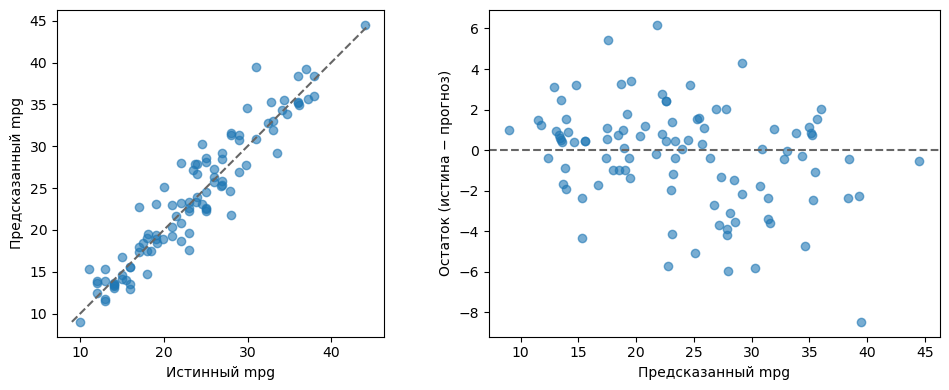

In [10]:
prediction = chosen.predict(X_test)
residuals = y_test - prediction
limits = [
    min(y_test.min(), prediction.min()),
    max(y_test.max(), prediction.max()),
]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.scatter(y_test, prediction, alpha=0.6)
left.plot(limits, limits, "--", color="0.4")
left.set(xlabel="Истинный mpg", ylabel="Предсказанный mpg")
left.set_aspect("equal", adjustable="box")
right.scatter(prediction, residuals, alpha=0.6)
right.axhline(0, ls="--", color="0.4")
right.set(xlabel="Предсказанный mpg", ylabel="Остаток (истина − прогноз)")
fig.tight_layout()
plt.show()

Точки ниже диагонали на левом графике соответствуют заниженному прогнозу.
На правом графике им соответствует положительный остаток.

Есть ли диапазон предсказаний, где остатки чаще имеют один знак?